# Guided Assignment

We are building a small linear graph that calculates a vendor's average star rating and then uses an LLM to write a one-line note to that vendor.

Make sure your `.env` file is present in this folder and has your OpenRouter key (`OPENROUTER_API_KEY`).

In [1]:
%pip install -q langgraph langchain_openai langchain_core python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [25]:
import os
import dotenv
from typing import TypedDict
from urllib.parse import urlparse
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langchain_core.output_parsers import StrOutputParser
from IPython.display import Image, display

dotenv.load_dotenv(".env")

raw_base_url = os.getenv("OPENROUTER_BASE_URL", "https://openrouter.ai/api/v1")
openrouter_base_url = raw_base_url.strip().strip('"').strip("'")
parsed = urlparse(openrouter_base_url)
if not parsed.scheme or not parsed.netloc:
    openrouter_base_url = "https://openrouter.ai/api/v1"

llm = ChatOpenAI(
    openai_api_key=os.getenv("OPENROUTER_API_KEY"),
    openai_api_base=openrouter_base_url,
    model_name="gpt-4o-mini-2024-07-18",
)

# Node 1: calculates the average rating from total stars and number of reviews
def calculate_avg_rating(state):
    state["avg_rating"] = round(state["total_stars"] / state["num_reviews"], 2)
    return state

# Node 2: asks the LLM to write a one-line note to the vendor about its rating
def write_vendor_note(state):
    prompt = f"Write a one-line note to vendor {state['vendor_id']} about their average rating of {state['avg_rating']} out of 5."
    try:
        state["vendor_note"] = (llm | StrOutputParser()).invoke(prompt)
    except Exception:
        state["vendor_note"] = (
            f"Vendor {state['vendor_id']}: your average rating is {state['avg_rating']} out of 5. Keep improving and thank you for serving your customers."
        )
    return state

In [26]:
# Step 1: Define a state class VendorState with vendor_id (str), total_stars (int), num_reviews (int), avg_rating (float), vendor_note (str)
from typing import TypedDict
class VendorState(TypedDict):
    vendor_id: str
    total_stars: int
    num_reviews: int
    avg_rating: float
    vendor_note: str


In [27]:
# Step 2: Create an empty StateGraph called graph using VendorState


graph = StateGraph(VendorState)

def calculate_avg_rating(state):
    state["avg_rating"] = round(state["total_stars"] / state["num_reviews"], 2)
    return state

def write_vendor_note(state):
    prompt = f"Write a one-line note to vendor {state['vendor_id']} about their average rating of {state['avg_rating']} out of 5."
    try:
        state["vendor_note"] = (llm | StrOutputParser()).invoke(prompt)
    except Exception:
        state["vendor_note"] = (
            f"Vendor {state['vendor_id']}: your average rating is {state['avg_rating']} out of 5. Keep improving and thank you for serving your customers."
        )
    return state

In [28]:
# Step 3: Add the two nodes "calculate_avg_rating" and "write_vendor_note" using the functions from the setup cell
graph.add_node("calculate_avg_rating", calculate_avg_rating);

graph.add_node("write_vendor_note", write_vendor_note);

In [29]:
# Step 4: Add edges START -> calculate_avg_rating -> write_vendor_note -> END

graph.add_edge(START, "calculate_avg_rating")

graph.add_edge("calculate_avg_rating", "write_vendor_note")

graph.add_edge("write_vendor_note", END)

In [30]:
# Step 5: Compile the graph into workflow
workflow = graph.compile()

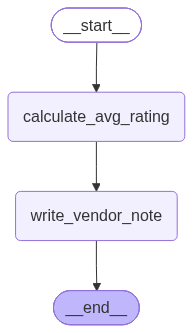

In [31]:
display(Image(workflow.get_graph().draw_mermaid_png()))

In [32]:
# Step 6: Call workflow.invoke() with vendor_id "V3", total_stars=1840, num_reviews=460
workflow.invoke({"vendor_id": "V3", "total_stars": 1840, "num_reviews": 460})

{'vendor_id': 'V3',
 'total_stars': 1840,
 'num_reviews': 460,
 'avg_rating': 4.0,
 'vendor_note': 'Vendor V3: your average rating is 4.0 out of 5. Keep improving and thank you for serving your customers.'}